In [56]:
import torch
import torchvision
from numpy.ma.core import size
from torch import nn
from torchvision import transforms
from torchvision import datasets
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt
import numpy as np

print(torchvision.__version__)

0.29.0+cu126


In [57]:
#Gettiing a dataset
train_data = datasets.FashionMNIST(root="data",
                                   train=True,
                                   download=True,
                                   transform=ToTensor(),
                                   target_transform=None)

test_data = datasets.FashionMNIST(root="data",
                                  train=False,
                                  download=True,
                                  transform=ToTensor(),
                                  target_transform=None)

In [58]:
len(train_data),len(test_data)

(60000, 10000)

In [59]:
image,label = train_data[0]
image,label

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000, 0.0039, 

In [60]:
class_names = train_data.classes
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [61]:
class_to_idx = train_data.class_to_idx
class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

In [62]:
#check the shape
image.shape, label

(torch.Size([1, 28, 28]), 9)

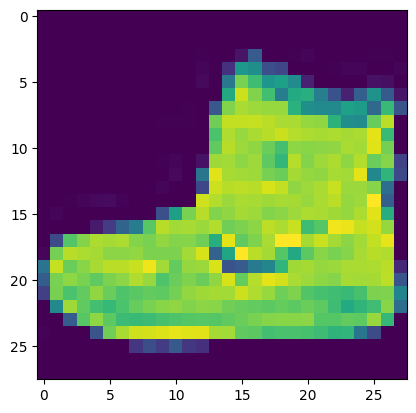

In [63]:
plt.imshow(image.squeeze())

Text(0.5, 1.0, 'Ankle boot')

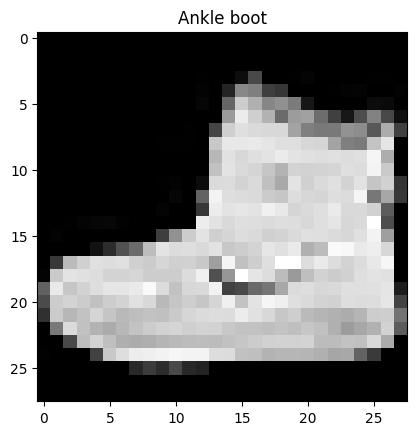

In [64]:
plt.imshow(image.squeeze(), cmap="gray")
plt.title("Ankle boot")

In [65]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

37542
46067
46876
46414
10026
27335
38620
11924
14950
57113
31378
29014
47210
18954
18231
47572


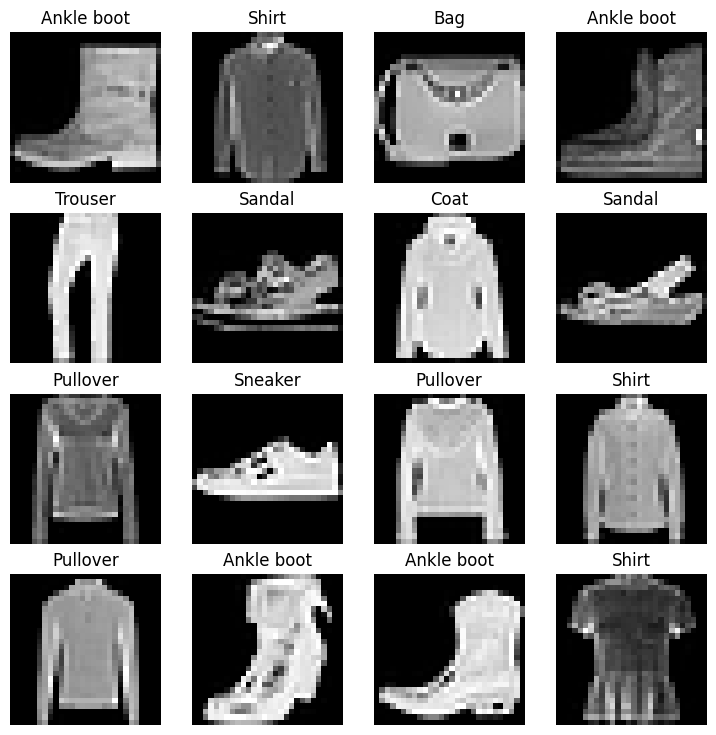

In [66]:
fig = plt.figure(figsize=(9,9))
rows,cols = 4,4
for i in range(1, rows*cols+1):
    random_idx = torch.randint(0,len(train_data),size=[1]).item()
    print(random_idx)
    img, label = train_data[random_idx]
    fig.add_subplot(rows, cols, i)
    plt.imshow(img.squeeze(), cmap="gray")
    plt.title(class_names[label])
    plt.axis(False)

In [67]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32
train_dataloader = DataLoader(dataset=train_data,
                              batch_size=BATCH_SIZE,
                              shuffle=True)

test_dataloader = DataLoader(dataset=test_data,
                             batch_size=BATCH_SIZE,
                             shuffle=False)
print(f"{train_dataloader}\n{test_dataloader}")


In [68]:
train_features_batch, train_labels_batch = next(iter(train_dataloader))
train_features_batch.shape, train_labels_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

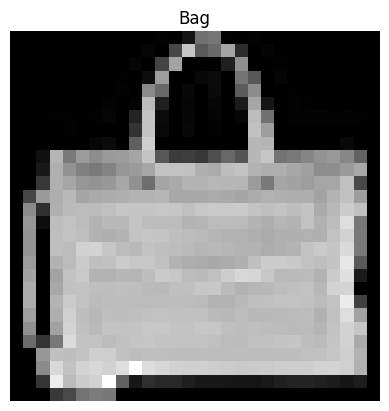

In [69]:
random_idx = torch.randint(0,len(train_features_batch),size=[1]).item()
img,label = train_features_batch[random_idx], train_labels_batch[random_idx]
plt.imshow(img.squeeze(), cmap="gray")
plt.title(class_names[label])
plt.axis(False)

In [70]:
flatten_model = nn.Flatten()

x=train_features_batch[0]
output = flatten_model(x)
x.shape,output.shape

(torch.Size([1, 28, 28]), torch.Size([1, 784]))

In [71]:
class FashionMNISTModelV0(nn.Module):
    def __init__(self,
                input_shape: int,
                hidden_units: int,
                output_shape: int):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_shape, out_features=hidden_units),
            nn.Linear(in_features=hidden_units,out_features=output_shape)
        )
    def forward(self, x):
        return self.layer_stack(x)


In [72]:
torch.manual_seed(42)
model0 = FashionMNISTModelV0(input_shape=28*28,hidden_units=10,output_shape=len(class_names)).to("cpu")

In [73]:
dummy_x = torch.rand([1,1,28,28])
model0(dummy_x)

tensor([[-0.0315,  0.3171,  0.0531, -0.2525,  0.5959,  0.2112,  0.3233,  0.2694,
         -0.1004,  0.0157]], grad_fn=<AddmmBackward0>)

In [74]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model0.parameters(),lr=0.1)
def accuracy_fn(y_true,y_pred):
    correct = torch.eq(y_true,y_pred).sum().item()
    acc = (correct/len(y_true)) * 100
    return acc

In [75]:
from timeit import default_timer
def print_train_time(start: float,
                     end: float,
                     device: torch.device = None):
    total_time = end - start
    print(f"Total time on {device}: {total_time:.3f} sec")
    return total_time

In [76]:
from tqdm.auto import tqdm


torch.manual_seed(42)
train_time_start = default_timer()

epochs = 3

for epoch in tqdm(range(epochs)):
    print(f"Epoch: {epoch}\n --------")

    train_loss = 0

    for batch, (X, y) in enumerate(train_dataloader):
        model0.train()
        y_pred = model0(X)
        loss = loss_fn(y_pred, y)
        train_loss += loss

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        if batch % 400 == 0:
            print(f"Looked at {batch * len(X)/len(train_dataloader.dataset)} sample.")


    train_loss /= len(train_dataloader)

    #Testing
    test_loss, test_acc = 0, 0
    model0.eval()
    with torch.inference_mode():
        for X_test,y_test in test_dataloader:
            test_pred = model0(X_test)

            test_loss += loss_fn(test_pred,y_test)

            test_acc += accuracy_fn(y_true=y_test,y_pred=test_pred.argmax(dim=1))

        test_loss /= len(test_dataloader)
        test_acc /= len(test_dataloader)

    print(f"Train loss: {train_loss} | test loss: {test_loss} | test acc: {test_acc}")

train_time_end = default_timer()
total_train_time_model0 = print_train_time(start=train_time_start,
                                           end=train_time_end,
                                           device=str(next(model0.parameters())))


  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
 --------
Looked at 0.0 sample.
Looked at 0.21333333333333335 sample.
Looked at 0.4266666666666667 sample.
Looked at 0.64 sample.
Looked at 0.8533333333333334 sample.


 33%|███▎      | 1/3 [00:07<00:15,  7.85s/it]

Train loss: 0.5903892517089844 | test loss: 0.509535014629364 | test acc: 82.03873801916933
Epoch: 1
 --------
Looked at 0.0 sample.
Looked at 0.21333333333333335 sample.
Looked at 0.4266666666666667 sample.
Looked at 0.64 sample.
Looked at 0.8533333333333334 sample.


 67%|██████▋   | 2/3 [00:15<00:07,  7.59s/it]

Train loss: 0.4763319790363312 | test loss: 0.47989004850387573 | test acc: 83.19688498402556
Epoch: 2
 --------
Looked at 0.0 sample.
Looked at 0.21333333333333335 sample.
Looked at 0.4266666666666667 sample.
Looked at 0.64 sample.
Looked at 0.8533333333333334 sample.


100%|██████████| 3/3 [00:23<00:00,  7.84s/it]

Train loss: 0.4550333023071289 | test loss: 0.4766388535499573 | test acc: 83.42651757188499
Total time on Parameter containing:
tensor([[ 0.0273,  0.0298, -0.0065,  ...,  0.0071,  0.0091,  0.0170],
        [-0.0189, -0.0355,  0.0155,  ...,  0.0161,  0.0120,  0.0117],
        [-0.0008,  0.0020,  0.0032,  ...,  0.0058, -0.0146,  0.0084],
        ...,
        [-0.0116,  0.0274, -0.0323,  ...,  0.0527,  0.0434,  0.0006],
        [-0.0231,  0.0252,  0.0236,  ..., -0.0892, -0.0385, -0.0071],
        [ 0.0175, -0.0148,  0.0027,  ..., -0.1155, -0.0674,  0.0125]],
       requires_grad=True): 23.521 sec


In [77]:
torch.manual_seed(42)
def eval_model(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               accuracy_fn,
               device: torch.device):
    loss, acc = 0, 0
    model.eval()
    with torch.inference_mode():
        for X,y in data_loader:
            X, y = X.to(device), y.to(device)
            y_pred = model(X)

            loss += loss_fn(y_pred, y)
            acc += accuracy_fn(y_true=y,y_pred=y_pred.argmax(dim=1))

        loss /= len(data_loader)
        acc/= len(data_loader)
    return {"model_name": model.__class__.__name__,
            "model_loss": loss.item(),
            "model_acc": acc}
model0_results = eval_model(model=model0,
                            data_loader=test_dataloader,
                            loss_fn=loss_fn,
                            accuracy_fn=accuracy_fn,
                            device="cpu")
model0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.4766388535499573,
 'model_acc': 83.42651757188499}

In [78]:
class FashionMNISTModelV1(nn.Module):
    def __init__(self,
                input_shape: int,
                hidden_units: int,
                output_shape: int):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_shape, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=output_shape),
            nn.ReLU()
        )
    def forward(self, x:torch.Tensor):
        return self.layer_stack(x)

device = "cuda" if torch.cuda.is_available() else "cpu"
model1 = FashionMNISTModelV1(input_shape=28*28,hidden_units=10,output_shape=len(class_names)).to(device)

In [79]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model1.parameters(), lr=0.1)

In [80]:
def train_step(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               accuracy_fn,
               device: torch.device):
    """Performs a training with model trying to lean on data_loader"""
    train_loss,train_acc = 0, 0
    model.train()

    for batch, (X,y) in enumerate(data_loader):
        X, y = X.to(device), y.to(device)
        y_pred = model(X)
        loss = loss_fn(y_pred,y)
        train_loss += loss
        train_acc += accuracy_fn(y, y_pred.argmax(dim=1))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    train_loss /= len(data_loader)
    train_acc /= len(data_loader)
    print(f"Train loss: {train_loss} | Train acc: {train_acc}")

In [81]:
def test_step(model:torch.nn.Module,
              data_loader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              accuracy_fn,
              device: torch.device):
    """Performs a testing loop step on model going over data_loader"""
    test_loss,test_acc = 0,0

    model.eval()

    with torch.inference_mode():
        for X,y in data_loader:
            X,y = X.to(device), y.to(device)

            test_pred = model(X)
            test_loss += loss_fn(test_pred, y)
            test_acc += accuracy_fn(y, test_pred.argmax(dim=1))


        test_loss /= len(data_loader)
        test_acc /= len(data_loader)
        print(f"Test loss: {test_loss} | Test acc: {test_acc}")


In [82]:
torch.manual_seed(42)

epochs = 3
train_time_start = timer()
for epoch in tqdm(range(epochs)):
    print(f"Epoch: {epoch}\n")
    train_step(model=model1,
               data_loader=train_dataloader,
               loss_fn=loss_fn,
               optimizer=optimizer,
               accuracy_fn=accuracy_fn,
               device=device)
    test_step(model=model1,
              data_loader=test_dataloader,
              loss_fn=loss_fn,
              accuracy_fn=accuracy_fn,
              device=device)
    train_time_end = timer()
    total_train_time_model1 = print_train_time(start=train_time_start,
                                               end=train_time_end,
                                               device="cuda")

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0

Train loss: 0.9824767112731934 | Train acc: 65.06


 33%|███▎      | 1/3 [00:12<00:25, 12.81s/it]

Test loss: 0.7606036067008972 | Test acc: 72.8035143769968
Total time on cuda: 12.807 sec
Epoch: 1

Train loss: 0.7036632895469666 | Train acc: 74.48


 67%|██████▋   | 2/3 [00:24<00:11, 11.96s/it]

Test loss: 0.7173149585723877 | Test acc: 73.67212460063898
Total time on cuda: 24.174 sec
Epoch: 2

Train loss: 0.6737506985664368 | Train acc: 75.305


100%|██████████| 3/3 [00:36<00:00, 12.09s/it]

Test loss: 0.6917039155960083 | Test acc: 74.810303514377
Total time on cuda: 36.273 sec


In [83]:
model1_results = eval_model(model=model1,
                            data_loader=test_dataloader,
                            loss_fn=loss_fn,
                            accuracy_fn=accuracy_fn,
                            device="cuda")
model1_results

{'model_name': 'FashionMNISTModelV1',
 'model_loss': 0.6917039155960083,
 'model_acc': 74.810303514377}

In [84]:
class FashionMNISTModelV2(nn.Module):
    def __init__(self,
                 input_shape: int,
                 hidden_units: int,
                 output_shape: int):
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden_units*7*7,
                      out_features=output_shape)
        )

    def forward(self,x):
        x = self.conv_block_1(x)
        #print(x.shape)
        x = self.conv_block_2(x)
        #print(x.shape)
        return self.classifier(x)

In [85]:
model2 = FashionMNISTModelV2(input_shape=1,
                             hidden_units=10,
                             output_shape=len(class_names)).to("cuda")

In [86]:
model2

FashionMNISTModelV2(
  (conv_block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

In [87]:
rand_image_tensor = torch.randn(size=(1,28,28))
rand_image_tensor.shape

torch.Size([1, 28, 28])

Unutrasnje vrednosti matrica moraju da se poklapaju

In [88]:
model2(rand_image_tensor.unsqueeze(0).to("cuda"))

tensor([[-0.0414, -0.0358, -0.0095,  0.0051,  0.0772,  0.0065, -0.0269,  0.0744,
         -0.0388, -0.0228]], device='cuda:0', grad_fn=<AddmmBackward0>)

In [89]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model2.parameters(),lr=0.1)

In [90]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

from timeit import default_timer as timer

train_time_start = timer()

epochs = 3
for epoch in tqdm(range(epochs)):
    print(f"Epoch: {epoch}")
    train_step(model=model2,
               data_loader=train_dataloader,
               loss_fn=loss_fn,
               optimizer=optimizer,
               accuracy_fn=accuracy_fn,
               device="cuda")
    test_step(model=model2,
              loss_fn=loss_fn,
              data_loader=test_dataloader,
              accuracy_fn=accuracy_fn,
              device="cuda")

    train_time_end = timer()
    total_train_time_model2 = print_train_time(start=train_time_start,
                                        end=train_time_end,
                                        device="cuda")



  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
Train loss: 0.5932239890098572 | Train acc: 78.24166666666666


 33%|███▎      | 1/3 [00:14<00:28, 14.01s/it]

Test loss: 0.3897378742694855 | Test acc: 85.99241214057508
Total time on cuda: 14.008 sec
Epoch: 1
Train loss: 0.3584709167480469 | Train acc: 87.105


 67%|██████▋   | 2/3 [00:27<00:13, 13.92s/it]

Test loss: 0.3491303622722626 | Test acc: 87.43011182108626
Total time on cuda: 27.874 sec
Epoch: 2
Train loss: 0.3229225277900696 | Train acc: 88.36333333333333


100%|██████████| 3/3 [00:41<00:00, 13.91s/it]

Test loss: 0.3442605435848236 | Test acc: 87.45007987220447
Total time on cuda: 41.736 sec


In [91]:
model2_results = eval_model(model=model2,
                            data_loader=test_dataloader,
                            loss_fn=loss_fn,
                            accuracy_fn=accuracy_fn,
                            device="cuda")
model2_results

{'model_name': 'FashionMNISTModelV2',
 'model_loss': 0.3442605435848236,
 'model_acc': 87.45007987220447}

In [92]:
model0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.4766388535499573,
 'model_acc': 83.42651757188499}

In [93]:
model1_results

{'model_name': 'FashionMNISTModelV1',
 'model_loss': 0.6917039155960083,
 'model_acc': 74.810303514377}

In [94]:
import pandas as pd

compare_results = pd.DataFrame([model0_results,
                                model1_results,
                                model2_results])
compare_results

,model_name,model_loss,model_acc
0,FashionMNISTModelV0,0.476639,83.426518
1,FashionMNISTModelV1,0.691704,74.810304
2,FashionMNISTModelV2,0.344261,87.450080


In [96]:
compare_results["training time"] = [total_train_time_model0,
                                    total_train_time_model1,
                                    total_train_time_model2]
compare_results

,model_name,model_loss,model_acc,training time
0,FashionMNISTModelV0,0.476639,83.426518,23.521099
1,FashionMNISTModelV1,0.691704,74.810304,36.273027
2,FashionMNISTModelV2,0.344261,87.450080,41.735662


In [97]:
def make_predictions(model: torch.nn.Module,
                     data: list,
                     device: torch.device):
    pred_probs = []
    model.eval()
    with torch.inference_mode():
        for sample in data:
            sample = torch.unsqueeze(sample, dim=0).to(device)

            pred_logits = model(sample)

            pred_prob = torch.softmax(pred_logits.squeeze(), dim=0)

            pred_probs.append(pred_prob.cpu())

    return torch.stack(pred_probs)



In [111]:
import random
# random.seed(42)
test_samples = []
test_labels = []
for sample, label in random.sample(list(test_data), k=9):
    test_samples.append(sample)
    test_labels.append(label)
test_samples[0].shape

torch.Size([1, 28, 28])

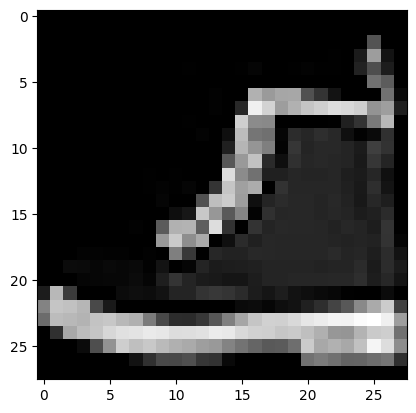

In [112]:
plt.imshow(test_samples[0].squeeze(), cmap="gray")

In [113]:
pred_probs = make_predictions(model=model2,
                              data=test_samples,
                              device="cuda")
pred_probs[:2]

tensor([[1.5872e-05, 1.1824e-06, 4.1065e-07, 4.5494e-06, 1.3870e-06, 3.9070e-02,
         3.4439e-06, 7.8852e-03, 5.5722e-04, 9.5246e-01],
        [8.1420e-06, 2.8633e-08, 4.6329e-07, 1.4390e-07, 1.3469e-06, 1.8296e-03,
         2.8231e-06, 9.9073e-01, 1.7948e-03, 5.6283e-03]])

In [114]:
#convert predictions probabilities to labels
pred_classes = pred_probs.argmax(dim=1)
print(pred_classes)
test_labels

tensor([9, 7, 2, 0, 1, 0, 3, 5, 4])


[9, 7, 2, 0, 1, 0, 4, 5, 4]

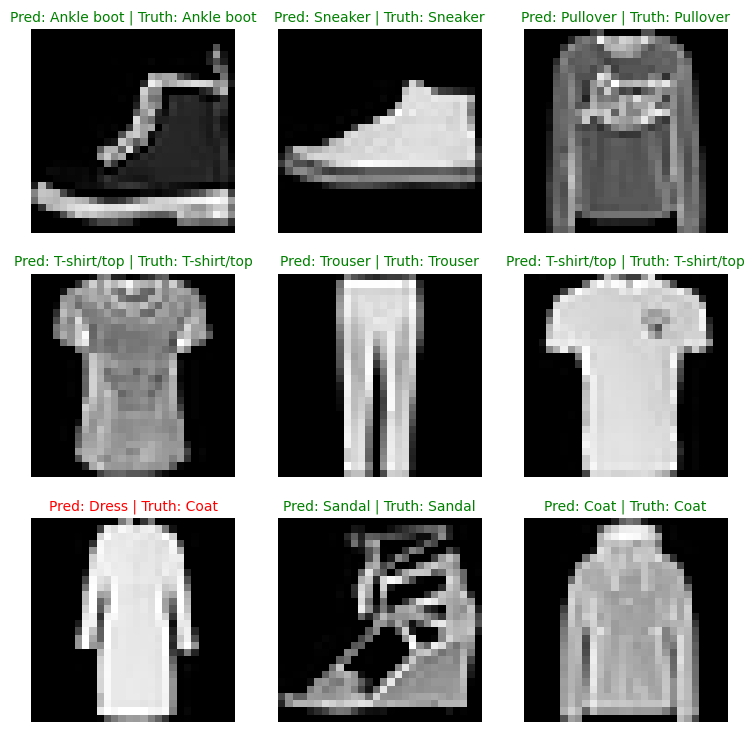

In [115]:
#plot predictions
plt.figure(figsize=(9,9))
nrows = 3
ncols = 3
for i, sample in enumerate(test_samples):
    plt.subplot(nrows,ncols, i+1)

    #plot the target image
    plt.imshow(sample.squeeze(), cmap="gray")
    pred_label = class_names[pred_classes[i]]
    truth_label = class_names[test_labels[i]]

    title_text = f"Pred: {pred_label} | Truth: {truth_label}"

    if pred_label == truth_label:
        plt.title(title_text,fontsize=10,c="g")
    else:
        plt.title(title_text, fontsize=10, c="r")
    plt.axis(False)

In [116]:
y_preds = []
model2.eval()
with torch.inference_mode():
    for X,y in tqdm(test_dataloader, desc="Making predictions..."):
        X,y = X.to("cuda"), y.to("cuda")
        y_logit = model2(X)
        y_pred = torch.softmax(y_logit.squeeze(), dim=0).argmax(dim=1)
        y_preds.append(y_pred.cpu())

y_pred_tensor = torch.cat(y_preds)
y_pred_tensor

Making predictions...: 100%|██████████| 313/313 [00:01<00:00, 165.58it/s]


tensor([9, 2, 1,  ..., 8, 1, 7])

In [117]:
len(y_pred_tensor)

10000

In [119]:
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

In [121]:
confmat = ConfusionMatrix(num_classes=len(class_names),
                          task="multiclass")
confmat_tensor = confmat(preds=y_pred_tensor,
                         target=test_data.targets)


In [122]:
confmat_tensor

tensor([[657,   5,  17,  78,   8,   1, 228,   0,   6,   0],
        [ 15, 860,  10,  88,  17,   0,   5,   0,   4,   1],
        [  6,   2, 752,  22, 101,   0, 113,   0,   4,   0],
        [ 27,   9,  16, 859,  46,   0,  36,   0,   7,   0],
        [  9,   5, 106,  51, 716,   0, 106,   0,   7,   0],
        [ 10,   3,   0,   2,   1, 833,   9,  46,  72,  24],
        [ 83,   6, 104,  57, 103,   0, 636,   0,  11,   0],
        [  2,   1,   0,   0,   0,  29,   0, 903,   9,  56],
        [ 16,   2,  22,  12,   8,   8,  31,   7, 892,   2],
        [  0,   0,   2,   3,   0,  18,   2,  84,  15, 876]])

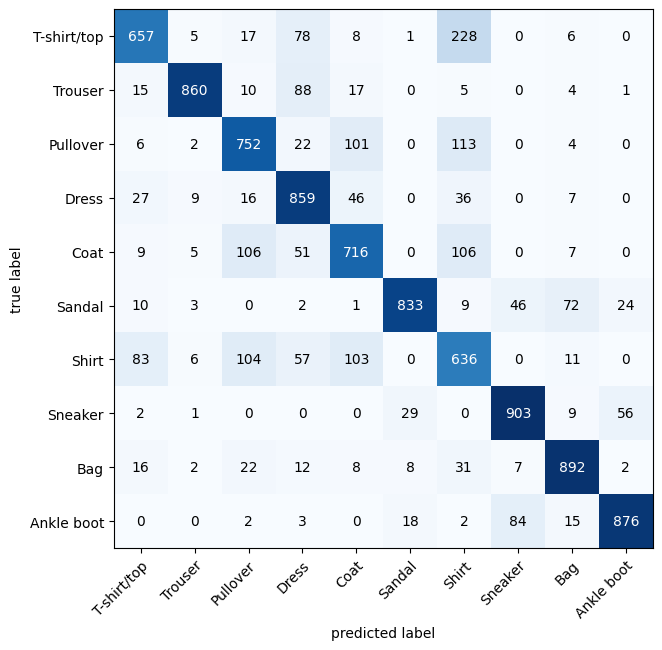

In [123]:
#plot the confusion metrics
fig, ax = plot_confusion_matrix(
    conf_mat=confmat_tensor.numpy(),
    class_names=class_names,
    figsize=(10,7
))

In [124]:
#Sad mogu da se vide greske koje model pravi